# TokenGate inference with and without vLLM

In this notebook, we'll use Qwen3 and Qwen3.5 to answer a question about a long passage. The answer is a single fact hidden among unrelated text. This task is called *needle-in-a-haystack retrieval* (NIAH).

[TokenGate](https://arxiv.org/abs/2610.26754) learns which input tokens to keep at an intermediate layer of the model. We control how many passage tokens survive with the budget $K$. For example, $K=64$ keeps 64 passage tokens, plus the instructions and question. The later layers then process this shorter sequence.

We'll try **$K=64$, $K=500$, and all passage tokens on both models**, using the same trained weights throughout. The **All tokens** setting keeps the gate active but disables pruning; it gives us a reference for measuring the speedup from retaining fewer tokens. For each budget, we'll compare the answer and latency from two implementations:

| Implementation | What we run |
|---|---|
| TokenGate (original) | This repository's inference code, with the trained gate and LoRA adapter. |
| TokenGate (vLLM) | Our vLLM integration, with the same gate and the adapter merged into the base weights. |

We'll first load the checkpoints and inspect the example, then run both implementations and plot the results.

## 1. Set up

Open this notebook in a fresh **Python 3.11–3.13 kernel on Linux**, with an idle NVIDIA GPU and the CUDA 13 toolkit (`nvcc`). The saved run used an A100 with 80 GB of memory.

First, request access to the [Qwen3 checkpoint](https://huggingface.co/luisgasparschroeder/tokengate-niah-qwen3-1.7b-gate1-seed0) and [Qwen3.5 checkpoint](https://huggingface.co/luisgasparschroeder/tokengate-niah-qwen3.5-2b-gate3-seed0). Once approved, use a Hugging Face token from that same account. The hidden prompt below also accepts it; the token is never saved in this notebook.

The next cell downloads the code from **[this TokenGate PR](https://github.com/token-gate-llms/TokenGate/pull/5)** and the [vLLM fork](https://github.com/luis-gasparschroeder/vllm/tree/lgs/tokengate), at fixed commits. It creates a separate environment for inference and builds the original TokenGate attention kernel. You do not need a local checkout. The first setup downloads several GB and can take a while; later runs reuse it.

Choose an idle device in `GPU`. We'll run all three settings on that device, one configuration at a time.


In [1]:
import os
import subprocess
import sys
from pathlib import Path

GPU = os.environ.get("TOKENGATE_DEMO_GPU", "0")
BUDGETS = (64, 500, "All")
REPEATS = 3
MAX_NEW_TOKENS = 1024
TOKEN_GATE_REVISION = "b47645f17e9767f52b4f33b99c133e678345b711"
CACHE = (
    Path(
        os.environ.get(
            "TOKENGATE_DEMO_CACHE",
            str(
                Path(os.environ.get("XDG_CACHE_HOME", Path.home() / ".cache"))
                / "tokengate-notebook"
            ),
        )
    )
    .expanduser()
    .resolve()
)
CACHE.mkdir(parents=True, exist_ok=True)
ROOT = CACHE / f"TokenGate-{TOKEN_GATE_REVISION}"

# The notebook itself needs only plotting, download, and display libraries.
with (CACHE / "notebook-dependencies.log").open("w") as log:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "rich==15.0.0",
            "cloudpickle==3.1.2",
            "huggingface_hub>=2.0,<3",
            "pandas",
            "matplotlib>=3.8",
            "seaborn==0.13.2",
            "ipywidgets",
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        check=True,
    )
from rich.console import Console

console = Console(width=110)

with console.status("Downloading the pinned TokenGate code..."):
    if not (ROOT / ".git").exists():
        subprocess.run(["git", "init", "-q", str(ROOT)], check=True)
        subprocess.run(
            [
                "git",
                "-C",
                str(ROOT),
                "remote",
                "add",
                "origin",
                "https://github.com/luis-gasparschroeder/TokenGate.git",
            ],
            check=True,
        )
        subprocess.run(
            [
                "git",
                "-C",
                str(ROOT),
                "fetch",
                "-q",
                "--depth=1",
                "origin",
                TOKEN_GATE_REVISION,
            ],
            check=True,
        )
        subprocess.run(
            ["git", "-C", str(ROOT), "checkout", "-q", "--detach", "FETCH_HEAD"],
            check=True,
        )
    actual = subprocess.check_output(
        ["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True
    ).strip()
    assert actual == TOKEN_GATE_REVISION, "Cached source has a different revision"
    subprocess.run(["git", "-C", str(ROOT), "diff", "--quiet", "HEAD"], check=True)

sys.path.insert(0, str(ROOT / "examples"))
from setup_inference_vllm import prepare_runtime

WORKER_PYTHON = prepare_runtime(ROOT, CACHE, GPU, console)
console.print(f"[green]Setup complete[/green] TokenGate {TOKEN_GATE_REVISION[:12]}")

Output()

Output()

Ready Pin vLLM

Output()

Ready Install CUDA PyTorch

Output()

... (6 outputs left out)

Ready Build TokenGate attention

Output()

Ready Check inference imports

Setup complete TokenGate b47645f17e97

In [2]:
%matplotlib inline

import getpass
import os
import sys
import tempfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import get_token
from huggingface_hub.utils import disable_progress_bars
from rich.console import Console
from rich.markdown import Markdown
from rich.panel import Panel
from rich.table import Table

console = Console(width=110)
disable_progress_bars()


def show_table(frame, title):
    table = Table(title=title, show_lines=False)
    for column in frame.columns:
        table.add_column(str(column))
    for row in frame.itertuples(index=False, name=None):
        table.add_row(*(str(value) for value in row))
    console.print(table)


from inference_vllm_utils import prepare_checkpoint, run_isolated, score_run


def retained_tokens(checkpoint, budget):
    sample = checkpoint["sample"]
    return sample["span_end"] - sample["span_start"] if budget == "All" else budget


def budget_label(budget):
    return "All tokens" if budget == "All" else f"K={budget}"


if not get_token():
    os.environ["HF_TOKEN"] = getpass.getpass("Hugging Face token: ")

OUTPUT = (
    Path(tempfile.gettempdir())
    / "tokengate-inference-example"
    / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
)
console.print(
    f"GPU: {GPU}, budgets: {BUDGETS}, 1 warm-up + {REPEATS} timed requests per configuration"
)
console.print(f"Run logs and measurements: {OUTPUT}")

GPU: 2, budgets: (64, 500, 'All'), 1 warm-up + 3 timed requests per configuration

Run logs and measurements: /future/u/luisgs/.tmp/tokengate-inference-example/20261106T031748Z

In [3]:
# Detect the hardware used by this notebook; no device model is hard-coded.
import csv
import json
import platform
import subprocess

cpu_info = {
    row["field"].rstrip(":"): row["data"]
    for row in json.loads(
        subprocess.check_output(
            ["lscpu", "--json"], text=True, env={**os.environ, "LC_ALL": "C"}
        )
    )["lscpu"]
}
ram_gib = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3
cpu = {
    "CPU model": cpu_info["Model name"],
    "Sockets": cpu_info["Socket(s)"],
    "Physical cores": int(cpu_info["Socket(s)"]) * int(cpu_info["Core(s) per socket"]),
    "Logical CPUs": cpu_info["CPU(s)"],
    "CPUs available to this process": len(os.sched_getaffinity(0)),
    "System RAM": f"{ram_gib:.1f} GiB",
    "OS / architecture": f"{platform.system()} {platform.release()} / {platform.machine()}",
}
show_table(
    pd.DataFrame(cpu.items(), columns=["Setting", "Detected value"]),
    "CPU configuration",
)
gpu_rows = list(
    csv.reader(
        subprocess.check_output(
            [
                "nvidia-smi",
                f"--id={GPU}",
                "--query-gpu=index,name,memory.total,driver_version",
                "--format=csv,noheader,nounits",
            ],
            text=True,
        ).splitlines(),
        skipinitialspace=True,
    )
)
gpu_configuration = pd.DataFrame(
    gpu_rows, columns=["GPU index", "GPU model", "VRAM (MiB)", "Driver"]
)
show_table(gpu_configuration, "Selected GPU configuration")

                         CPU configuration                          
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Setting                        ┃ Detected value                  ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ CPU model                      │ AMD EPYC 7742 64-Core Processor │
│ Sockets                        │ 2                               │
│ Physical cores                 │ 128                             │
│ Logical CPUs                   │ 256                             │
│ CPUs available to this process │ 256                             │
│ System RAM                     │ 1007.7 GiB                      │
│ OS / architecture              │ Linux 6.8.0-90-generic / x86_64 │
└────────────────────────────────┴─────────────────────────────────┘

                  Selected GPU configuration                  
┏━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ GPU index ┃ GPU model             ┃ VRAM (MiB) ┃ Driver    ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ 2         │ NVIDIA A100-SXM4-80GB │ 81920      │ 580.82.07 │
└───────────┴───────────────────────┴────────────┴───────────┘

## 2. Load the checkpoints

We'll load one trained checkpoint for each model. Qwen3 has its gate at layer 1 and Qwen3.5 at layer 3, counting from zero. Changing $K$ changes how many tokens the gate keeps at inference; it does not require another checkpoint.

Each download contains the gate and adapter, the vLLM export, and our test example. `prepare_checkpoint` downloads the base model and checks the files before we use them.

In [4]:
CHECKPOINTS = {
    "Qwen3-1.7B": {
        "repo_id": "luisgasparschroeder/tokengate-niah-qwen3-1.7b-gate1-seed0",
        "revision": "7c663e71d44252c57e88a1c6b5df9364fc8f7b79",
    },
    "Qwen3.5-2B": {
        "repo_id": "luisgasparschroeder/tokengate-niah-qwen3.5-2b-gate3-seed0",
        "revision": "783d8eabe61939c8ebdc7c59cccf6cc6b3f99a5d",
    },
}
assets = {}
for name, settings in CHECKPOINTS.items():
    with console.status(f"Downloading and verifying {name}..."):
        assets[name] = prepare_checkpoint(**settings)
    console.print(f"[green]Verified[/green] {name}")
show_table(
    pd.DataFrame(
        [
            {
                "Model": name,
                "Gate layer": a["manifest"]["gate_layer"],
                "Budgets to test": ", ".join(budget_label(k) for k in BUDGETS),
                "Prompt tokens": len(a["sample"]["input_ids"]),
                "Passage tokens (All)": retained_tokens(a, "All"),
                "Sample": a["sample"]["id"],
            }
            for name, a in assets.items()
        ]
    ),
    "Selected checkpoints",
)

Output()

Verified Qwen3-1.7B

Output()

Verified Qwen3.5-2B

                                            Selected checkpoints                                             
┏━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ Model      ┃ Gate layer ┃ Budgets to test         ┃ Prompt tokens ┃ Passage tokens (All) ┃ Sample         ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ Qwen3-1.7B │ 1          │ K=64, K=500, All tokens │ 15910         │ 15866                │ 0050_niah_test │
│ Qwen3.5-2B │ 3          │ K=64, K=500, All tokens │ 15907         │ 15859                │ 0050_niah_test │
└────────────┴────────────┴─────────────────────────┴───────────────┴──────────────────────┴────────────────┘

## 3. Look at the retrieval task

Let's inspect the question and the fact we're asking the model to find. The example below is the first test sample in our 16K split. Both models see the same passage and question, encoded with their own tokenizers.

The excerpt shows where the answer occurs in the passage. We display it here to make the task concrete; the model receives the full passage.

In [5]:
sample = assets["Qwen3-1.7B"]["sample"]
other = assets["Qwen3.5-2B"]["sample"]
assert all(sample[key] == other[key] for key in ("id", "body", "question", "answer"))
needle_at = sample["body"].lower().find(sample["answer"].lower())
assert needle_at >= 0
excerpt = sample["body"][
    max(0, needle_at - 90) : needle_at + len(sample["answer"]) + 90
]
console.print(
    Panel(
        Markdown(
            f"**Sample:** `{sample['id']}`, held-out test, 16K tier\n\n"
            f"**Question:** {sample['question']}\n\n"
            f"**Gold answer:** {sample['answer']}\n\n"
            f"**Around the needle:**\n\n> {excerpt.strip()}"
        ),
        title="The held-out retrieval task",
    )
)

╭─────────────────────────────────────── The held-out retrieval task ────────────────────────────────────────╮
│ Sample: 0050_niah_test, held-out test, 16K tier                                                            │
│                                                                                                            │
│ Question: What is the best thing to do in Chennai?                                                         │
│                                                                                                            │
│ Gold answer: climb the clocktower stairs at the terraced tea garden in the first snow                      │
│                                                                                                            │
│ Around the needle:                                                                                         │
│                                                                                                            │
│ ▌ they need to do their jobs? How do you recognize them? The best thing to do in Chennai is climb the      │
│ ▌ clocktower stairs at the terraced tea garden in the first snow. How do you get them to come and work     │
│ ▌ for you? And then of course there's the question, h                                                      │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## 4. Run the original TokenGate code

First, we'll load the base model, gate, and adapter with [`load_gate_model`](../tokengate/inference.py), then generate an answer with [`generate_batch`](../tokengate/e2e_gate/decode/gate_decode.py). The `keep_tokens` argument sets $K$ for this call.

For each model and budget, we make one warm-up call and time three more. We measure **time to first token (TTFT)** and **time to final token**, starting when we submit the tokenized prompt. Loading, tokenization, and text decoding are outside these timings.

Each configuration runs in a separate process so its GPU memory is released before the next one. The helper saves the complete answers and timings; the cell displays the first answer from each configuration.

In [6]:
def tokengate_inference(assets, keep_tokens, repeats, max_new_tokens):
    import time
    from pathlib import Path

    import torch
    from transformers import AutoTokenizer

    import tokengate
    from tokengate.e2e_gate.decode.gate_decode import TokenDelivery, generate_batch
    from tokengate.inference import load_gate_model

    meta, sample = assets["manifest"], assets["sample"]
    model, gate, _ = load_gate_model(
        assets["base"],
        str(Path(assets["package"]) / meta["gate_file"]),
        meta["gate_layer"],
        gate_attn=meta["research_attention"],
        warmup=False,
    )
    tokenizer = AutoTokenizer.from_pretrained(assets["base"])
    tokenizer.pad_token = tokenizer.eos_token
    runs = []
    for repetition in range(repeats + 1):
        delivery = TokenDelivery()
        torch.cuda.synchronize()
        start = time.perf_counter()
        output = generate_batch(
            model,
            gate,
            tokenizer,
            [sample["input_ids"]],
            [sample["span_start"]],
            [sample["span_end"]],
            meta["gate_layer"],
            keep_tokens,
            max_new_tokens,
            token_callback=delivery.put,
        )
        torch.cuda.synchronize()
        delivery_metrics = delivery.result(
            start, tokenizer.eos_token_id, max_new_tokens
        )
        assert output.token_ids[0] == delivery.token_ids
        if repetition:
            row = score_run(
                output.answers[0],
                output.token_ids[0],
                sample,
                delivery.first_time - start,
                delivery.last_time - start,
            )
            row["finish_reason"] = delivery_metrics["finish_reason"]
            row["retained_prompt_tokens"] = output.n_kepts[0]
            runs.append(row)
    return {
        "engine": "TokenGate (original)",
        "model": meta["run_id"],
        "K": keep_tokens,
        "sample_id": sample["id"],
        "runs": runs,
        "torch": torch.__version__,
        "source": tokengate.__file__,
        "gpu": torch.cuda.get_device_name(),
        "hub_revision": assets["revision"],
    }

In [7]:
tokengate_results = {}
for name, checkpoint in assets.items():
    for budget in BUDGETS:
        console.print(
            f"Running {name}, {budget_label(budget)}, with original TokenGate..."
        )
        result = run_isolated(
            tokengate_inference,
            checkpoint,
            keep_tokens=retained_tokens(checkpoint, budget),
            gpu=GPU,
            repeats=REPEATS,
            max_new_tokens=MAX_NEW_TOKENS,
            output_dir=OUTPUT,
            python=WORKER_PYTHON,
        )
        tokengate_results[name, budget] = result
        console.print(
            Panel(result["runs"][0]["answer"], title=f"{name}, {budget_label(budget)}")
        )

Running Qwen3-1.7B, K=64, with original TokenGate...

╭───────────────────────────────────────────── Qwen3-1.7B, K=64 ─────────────────────────────────────────────╮
│ climb the clocktower stairs at the terraced tea garden in the first snow                                   │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Running Qwen3-1.7B, K=500, with original TokenGate...

╭──────────────────────────────────────────── Qwen3-1.7B, K=500 ─────────────────────────────────────────────╮
│ climb the clocktower stairs at the terraced tea garden in the first snow                                   │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Running Qwen3-1.7B, All tokens, with original TokenGate...

╭────────────────────────────────────────── Qwen3-1.7B, All tokens ──────────────────────────────────────────╮
│ climb the clocktower stairs at the terraced tea garden in the first snow                                   │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

... (2 outputs left out)

Running Qwen3.5-2B, K=500, with original TokenGate...

╭──────────────────────────────────────────── Qwen3.5-2B, K=500 ─────────────────────────────────────────────╮
│ climb the clocktower stairs at the terraced tea garden in the first snow                                   │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Running Qwen3.5-2B, All tokens, with original TokenGate...

╭────────────────────────────────────────── Qwen3.5-2B, All tokens ──────────────────────────────────────────╮
│ climb the clocktower stairs at the terraced tea garden in the first snow                                   │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## 5. Run TokenGate in vLLM

Now we'll repeat the same calls with vLLM. We pass the same prompt tokens and budget, and mark the passage as the part that TokenGate may prune. Instructions and question tokens stay protected.

vLLM streams generated tokens back to Python, which lets us time the first and final token as they arrive. We use greedy decoding and one request at a time, as in the original implementation.

<details>
<summary>vLLM settings</summary>

The exported weights have the LoRA adapter merged into the base model. We use eager execution, synchronous GPU scheduling, complete prefill, and a 4 GiB KV cache pool. Prefix caching is disabled. The asynchronous Python API below is used to receive tokens as they become available.

</details>

In [8]:
def vllm_inference(assets, keep_tokens, repeats, max_new_tokens):
    import asyncio
    import time
    from pathlib import Path

    import vllm
    from transformers import AutoTokenizer
    from vllm import AsyncEngineArgs, SamplingParams
    from vllm.v1.engine.async_llm import AsyncLLM

    meta, sample = assets["manifest"], assets["sample"]
    model_path = str(Path(assets["package"]) / "vllm")
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    limit = len(sample["input_ids"]) + max_new_tokens
    settings = AsyncEngineArgs(
        model=model_path,
        dtype="bfloat16",
        generation_config="vllm",
        seed=0,
        enforce_eager=True,
        max_model_len=limit,
        max_num_batched_tokens=limit,
        max_num_scheduled_tokens=limit,
        long_prefill_token_threshold=0,
        max_num_seqs=1,
        async_scheduling=False,
        enable_chunked_prefill=False,
        enable_prefix_caching=False,
        mamba_cache_mode="none",
        kv_cache_memory_bytes=4 * 1024**3,
    )
    sampling = SamplingParams(
        temperature=0,
        max_tokens=max_new_tokens,
        detokenize=False,
        stop_token_ids=[tokenizer.eos_token_id],
        extra_args={
            "token_gate_version": 1,
            "token_gate_span_start": sample["span_start"],
            "token_gate_span_end": sample["span_end"],
            "token_gate_keep_tokens": keep_tokens,
        },
    )

    async def generate():
        engine = AsyncLLM.from_engine_args(settings)
        runs = []
        try:
            for repetition in range(repeats + 1):
                first = last = None
                start = time.perf_counter()
                async for output in engine.generate(
                    {"prompt_token_ids": sample["input_ids"]},
                    sampling,
                    request_id=f"example-{repetition}",
                ):
                    if output.outputs[0].token_ids:
                        last = time.perf_counter()
                        if first is None:
                            first = last
                assert output.finished and first is not None
                tokens = list(output.outputs[0].token_ids)
                if repetition:
                    answer = tokenizer.decode(tokens, skip_special_tokens=True)
                    row = score_run(answer, tokens, sample, first - start, last - start)
                    row["finish_reason"] = output.outputs[0].finish_reason
                    runs.append(row)
        finally:
            engine.shutdown()
        return runs

    return {
        "engine": "TokenGate (vLLM)",
        "model": meta["run_id"],
        "K": keep_tokens,
        "sample_id": sample["id"],
        "runs": asyncio.run(generate()),
        "vllm": vllm.__version__,
        "source": vllm.__file__,
        "hub_revision": assets["revision"],
    }

In [9]:
vllm_results = {}
for name, checkpoint in assets.items():
    for budget in BUDGETS:
        console.print(
            f"Running {name}, {budget_label(budget)}, with TokenGate in vLLM..."
        )
        result = run_isolated(
            vllm_inference,
            checkpoint,
            keep_tokens=retained_tokens(checkpoint, budget),
            gpu=GPU,
            repeats=REPEATS,
            max_new_tokens=MAX_NEW_TOKENS,
            output_dir=OUTPUT,
            python=WORKER_PYTHON,
        )
        vllm_results[name, budget] = result
        console.print(
            Panel(result["runs"][0]["answer"], title=f"{name}, {budget_label(budget)}")
        )

Running Qwen3-1.7B, K=64, with TokenGate in vLLM...

╭───────────────────────────────────────────── Qwen3-1.7B, K=64 ─────────────────────────────────────────────╮
│ climb the clocktower stairs at the terraced tea garden in the first snow                                   │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Running Qwen3-1.7B, K=500, with TokenGate in vLLM...

╭──────────────────────────────────────────── Qwen3-1.7B, K=500 ─────────────────────────────────────────────╮
│ climb the clocktower stairs at the terraced tea garden in the first snow                                   │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Running Qwen3-1.7B, All tokens, with TokenGate in vLLM...

╭────────────────────────────────────────── Qwen3-1.7B, All tokens ──────────────────────────────────────────╮
│ climb the clocktower stairs at the terraced tea garden in the first snow                                   │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

... (2 outputs left out)

Running Qwen3.5-2B, K=500, with TokenGate in vLLM...

╭──────────────────────────────────────────── Qwen3.5-2B, K=500 ─────────────────────────────────────────────╮
│ climb the clocktower stairs at the terraced tea garden in the first snow                                   │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Running Qwen3.5-2B, All tokens, with TokenGate in vLLM...

╭────────────────────────────────────────── Qwen3.5-2B, All tokens ──────────────────────────────────────────╮
│ climb the clocktower stairs at the terraced tea garden in the first snow                                   │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## 6. Compare the results

Let's check the answers before comparing speed. An answer counts as correct if it contains the expected phrase after normalization. We also check whether the two implementations generated the same tokens and whether the three repetitions agree.

The latency values below are medians of the three timed calls. Accuracy is measured on **one test example**: $1/1$ means the model found the answer, and $0/1$ means it missed it. Repeating that example for timing does not make the accuracy estimate more reliable.

Each panel includes **All tokens** alongside $K=64$ and $K=500$. Compare bars of the same color to see the effect of pruning. Speedup is the all-token latency divided by the pruned latency, computed separately for each model and implementation:

$$\text{speedup}(K) = \frac{T_{\mathrm{All}}}{T_K}.$$

For example, $2\times$ means that the pruned run took half as long. Compare blue and orange at the same budget to compare implementations.

In [10]:
records, agreement = [], []
for name, checkpoint in assets.items():
    for budget in BUDGETS:
        reference = tokengate_results[name, budget]
        serving = vllm_results[name, budget]
        agreement.append(
            {
                "Model": name,
                "K": budget,
                "Identical engine outputs": all(
                    a["token_ids"] == b["token_ids"]
                    for a, b in zip(reference["runs"], serving["runs"], strict=True)
                ),
            }
        )
        for result in (reference, serving):
            assert result["K"] == retained_tokens(checkpoint, budget)
            runs = result["runs"]
            stable = all(row["token_ids"] == runs[0]["token_ids"] for row in runs)
            records.append(
                {
                    "Model": name,
                    "Engine": result["engine"],
                    "K": budget,
                    "Retrieved needle": "Yes"
                    if all(row["correct"] for row in runs)
                    else "No"
                    if not any(row["correct"] for row in runs)
                    else "Varies",
                    "Repeat stability": stable,
                    "Output tokens": ", ".join(
                        str(x)
                        for x in sorted({row["generated_tokens"] for row in runs})
                    ),
                    "Stop": ", ".join(sorted({row["finish_reason"] for row in runs})),
                    "TTFT (ms)": np.median([row["ttft_ms"] for row in runs]),
                    "Generation (ms)": np.median([row["total_ms"] for row in runs]),
                }
            )
summary = pd.DataFrame(records)
for name in assets:
    for engine in summary["Engine"].unique():
        mask = (summary["Model"] == name) & (summary["Engine"] == engine)
        baseline = summary[mask & (summary["K"] == "All")].iloc[0]
        summary.loc[mask, "TTFT speedup"] = (
            baseline["TTFT (ms)"] / summary.loc[mask, "TTFT (ms)"]
        )
        summary.loc[mask, "Generation speedup"] = (
            baseline["Generation (ms)"] / summary.loc[mask, "Generation (ms)"]
        )
show_table(
    summary[["Model", "K", "Engine", "Retrieved needle", "Output tokens", "Stop"]],
    "Answer quality",
)
show_table(
    summary[
        [
            "Model",
            "K",
            "Engine",
            "TTFT (ms)",
            "Generation (ms)",
            "TTFT speedup",
            "Generation speedup",
        ]
    ].round(2),
    "Median latency and speedup over All tokens (three calls)",
)
show_table(summary[["Model", "K", "Engine", "Repeat stability"]], "Repeat stability")
show_table(pd.DataFrame(agreement), "Generated-token agreement")

                                   Answer quality                                    
┏━━━━━━━━━━━━┳━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━┓
┃ Model      ┃ K   ┃ Engine               ┃ Retrieved needle ┃ Output tokens ┃ Stop ┃
┡━━━━━━━━━━━━╇━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━┩
│ Qwen3-1.7B │ 64  │ TokenGate (original) │ Yes              │ 17            │ stop │
│ Qwen3-1.7B │ 64  │ TokenGate (vLLM)     │ Yes              │ 17            │ stop │
│ Qwen3-1.7B │ 500 │ TokenGate (original) │ Yes              │ 17            │ stop │
│ Qwen3-1.7B │ 500 │ TokenGate (vLLM)     │ Yes              │ 17            │ stop │
│ Qwen3-1.7B │ All │ TokenGate (original) │ Yes              │ 17            │ stop │
│ Qwen3-1.7B │ All │ TokenGate (vLLM)     │ Yes              │ 17            │ stop │
│ Qwen3.5-2B │ 64  │ TokenGate (original) │ Yes              │ 17            │ stop │
│ Qwen3.5-2B │ 64  │ TokenGate (vLLM)     │ Yes              │ 17            │ stop │
│ Qwen3.5-2B │ 500 │ TokenGate (original) │ Yes              │ 17            │ stop │
│ Qwen3.5-2B │ 500 │ TokenGate (vLLM)     │ Yes              │ 17            │ stop │
│ Qwen3.5-2B │ All │ TokenGate (original) │ Yes              │ 17            │ stop │
│ Qwen3.5-2B │ All │ TokenGate (vLLM)     │ Yes              │ 17            │ stop │
└────────────┴─────┴──────────────────────┴──────────────────┴───────────────┴──────┘

                          Median latency and speedup over All tokens (three calls)                           
┏━━━━━━━━━━━━┳━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ Model      ┃ K   ┃ Engine               ┃ TTFT (ms) ┃ Generation (ms) ┃ TTFT speedup ┃ Generation speedup ┃
┡━━━━━━━━━━━━╇━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ Qwen3-1.7B │ 64  │ TokenGate (original) │ 74.23     │ 681.3           │ 7.49         │ 1.87               │
│ Qwen3-1.7B │ 64  │ TokenGate (vLLM)     │ 48.02     │ 549.63          │ 22.55        │ 2.86               │
│ Qwen3-1.7B │ 500 │ TokenGate (original) │ 73.98     │ 682.41          │ 7.51         │ 1.87               │
│ Qwen3-1.7B │ 500 │ TokenGate (vLLM)     │ 58.41     │ 549.98          │ 18.54        │ 2.86               │
│ Qwen3-1.7B │ All │ TokenGate (original) │ 555.82    │ 1276.79         │ 1.0          │ 1.0                │
│ Qwen3-1.7B │ All │ TokenGate (vLLM)     │ 1082.67   │ 1573.14         │ 1.0          │ 1.0                │
│ Qwen3.5-2B │ 64  │ TokenGate (original) │ 117.72    │ 618.67          │ 4.23         │ 1.66               │
│ Qwen3.5-2B │ 64  │ TokenGate (vLLM)     │ 60.83     │ 359.33          │ 7.04         │ 2.08               │
│ Qwen3.5-2B │ 500 │ TokenGate (original) │ 117.52    │ 624.19          │ 4.23         │ 1.65               │
│ Qwen3.5-2B │ 500 │ TokenGate (vLLM)     │ 69.1      │ 367.5           │ 6.2          │ 2.03               │
│ Qwen3.5-2B │ All │ TokenGate (original) │ 497.45    │ 1028.85         │ 1.0          │ 1.0                │
│ Qwen3.5-2B │ All │ TokenGate (vLLM)     │ 428.47    │ 745.61          │ 1.0          │ 1.0                │
└────────────┴─────┴──────────────────────┴───────────┴─────────────────┴──────────────┴────────────────────┘

                       Repeat stability                       
┏━━━━━━━━━━━━┳━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ Model      ┃ K   ┃ Engine               ┃ Repeat stability ┃
┡━━━━━━━━━━━━╇━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ Qwen3-1.7B │ 64  │ TokenGate (original) │ True             │
│ Qwen3-1.7B │ 64  │ TokenGate (vLLM)     │ True             │
│ Qwen3-1.7B │ 500 │ TokenGate (original) │ True             │
│ Qwen3-1.7B │ 500 │ TokenGate (vLLM)     │ True             │
│ Qwen3-1.7B │ All │ TokenGate (original) │ True             │
│ Qwen3-1.7B │ All │ TokenGate (vLLM)     │ True             │
│ Qwen3.5-2B │ 64  │ TokenGate (original) │ True             │
│ Qwen3.5-2B │ 64  │ TokenGate (vLLM)     │ True             │
│ Qwen3.5-2B │ 500 │ TokenGate (original) │ True             │
│ Qwen3.5-2B │ 500 │ TokenGate (vLLM)     │ True             │
│ Qwen3.5-2B │ All │ TokenGate (original) │ True             │
│ Qwen3.5-2B │ All │ TokenGate (vLLM)     │ True             │
└────────────┴─────┴──────────────────────┴──────────────────┘

           Generated-token agreement           
┏━━━━━━━━━━━━┳━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Model      ┃ K   ┃ Identical engine outputs ┃
┡━━━━━━━━━━━━╇━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Qwen3-1.7B │ 64  │ True                     │
│ Qwen3-1.7B │ 500 │ True                     │
│ Qwen3-1.7B │ All │ True                     │
│ Qwen3.5-2B │ 64  │ True                     │
│ Qwen3.5-2B │ 500 │ True                     │
│ Qwen3.5-2B │ All │ True                     │
└────────────┴─────┴──────────────────────────┘

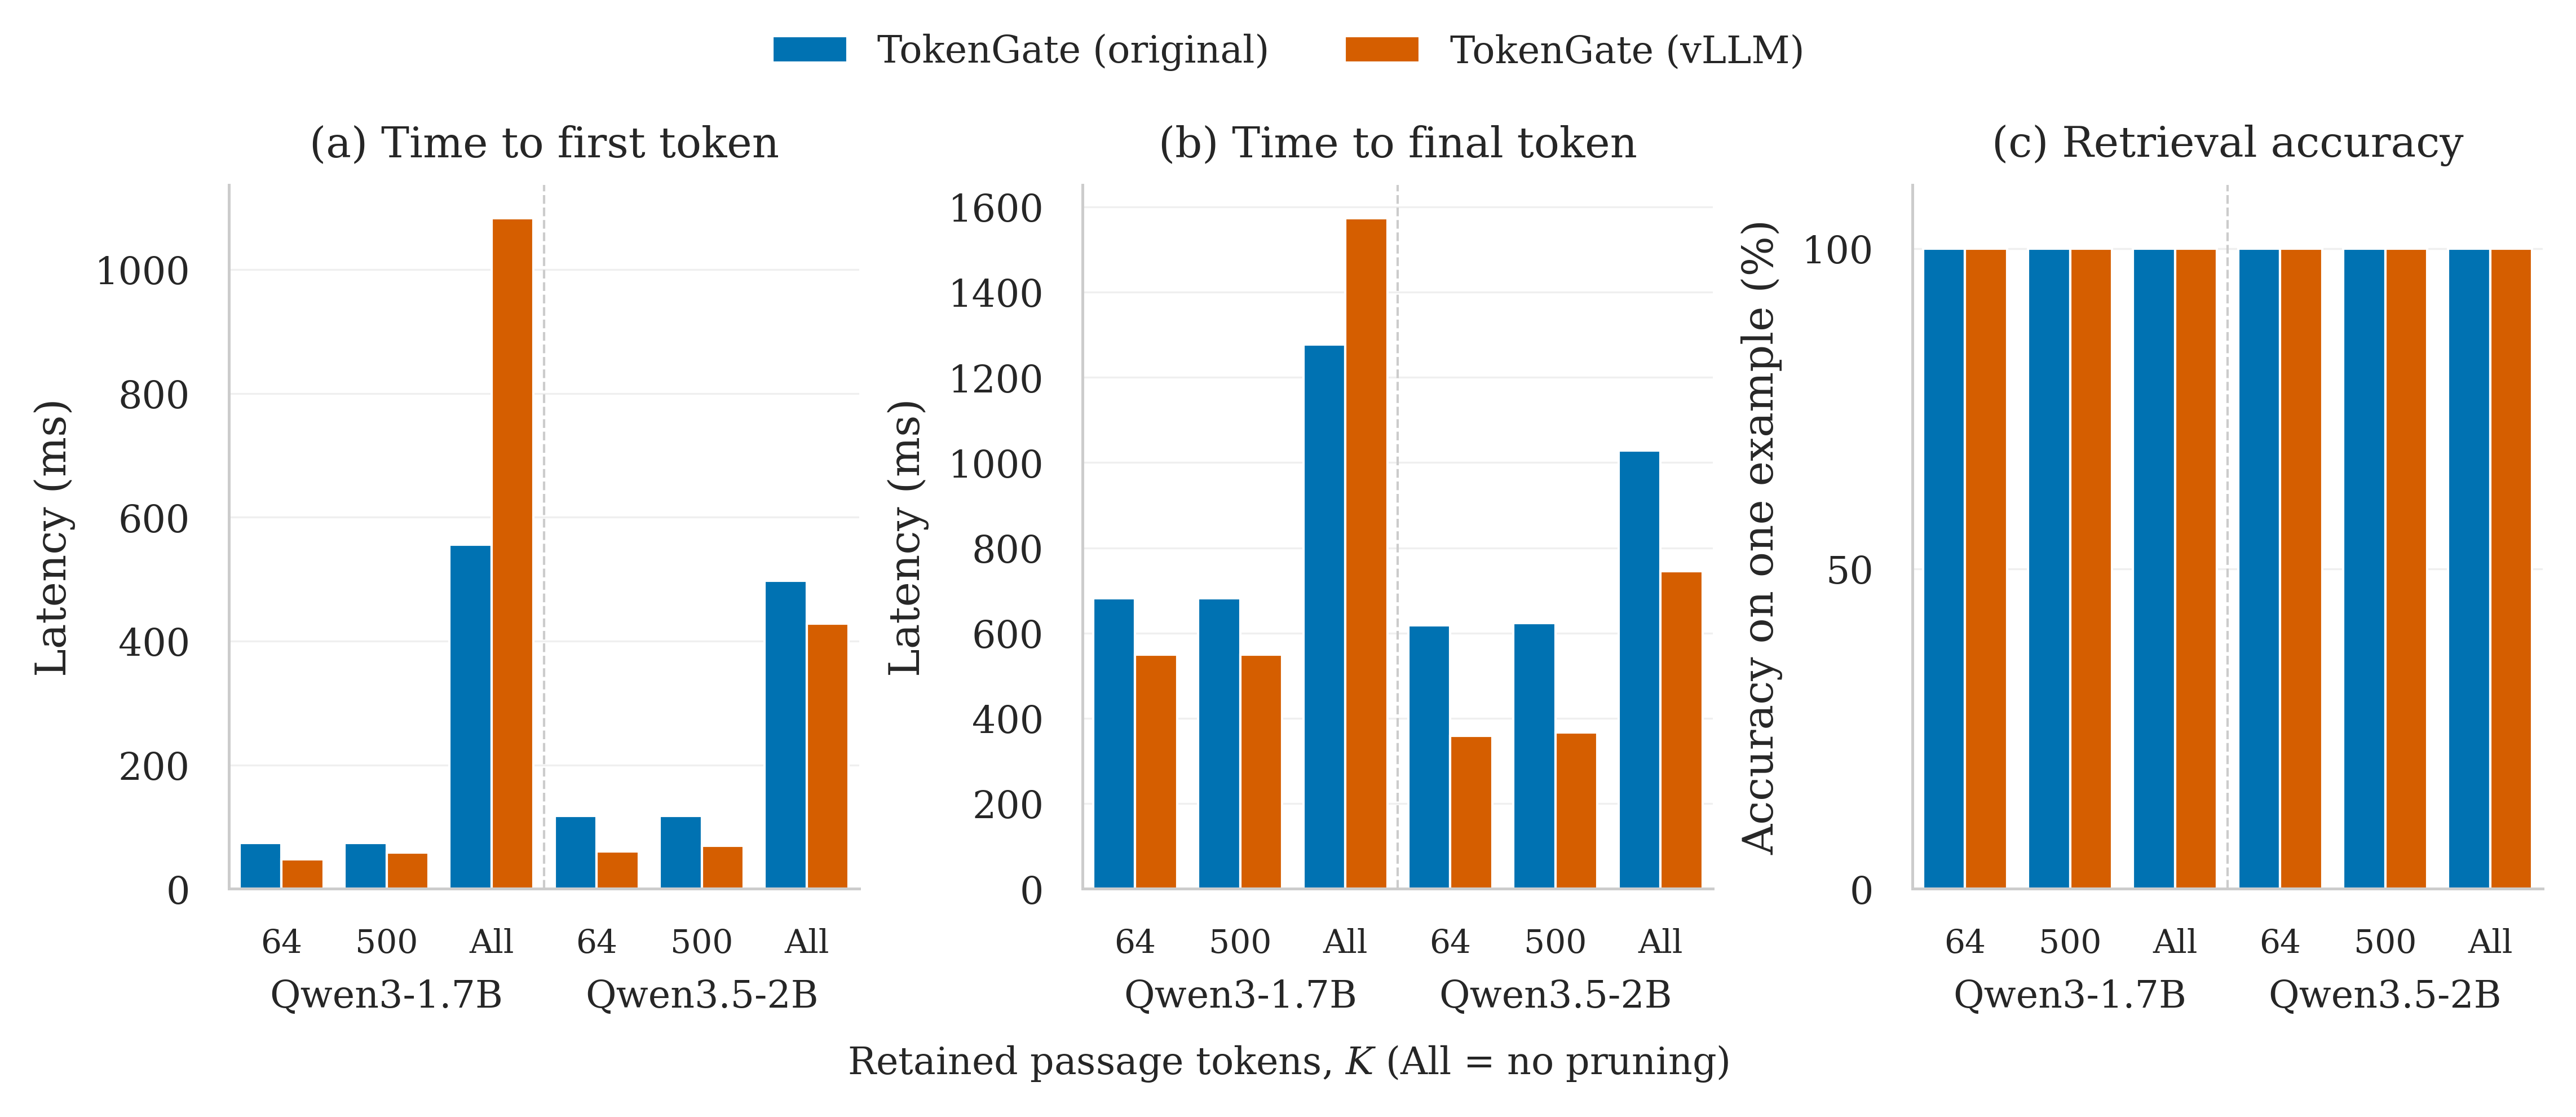

Qwen3-1.7B, K=64: vLLM / original generation latency = 0.81x.

Qwen3-1.7B, K=500: vLLM / original generation latency = 0.81x.

Qwen3-1.7B, All tokens: vLLM / original generation latency = 1.23x.

Qwen3.5-2B, K=64: vLLM / original generation latency = 0.58x.

Qwen3.5-2B, K=500: vLLM / original generation latency = 0.59x.

Qwen3.5-2B, All tokens: vLLM / original generation latency = 0.72x.

In [11]:
from IPython.display import Image, display

# One paper-width figure; medians only, without repetition markers.
sns.set_theme(
    context="paper",
    style="whitegrid",
    font="serif",
    font_scale=1.0,
    rc={
        "font.size": 9,
        "axes.titlesize": 9,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "axes.linewidth": 0.6,
        "grid.linewidth": 0.4,
        "grid.alpha": 0.3,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
        "mathtext.fontset": "dejavuserif",
        "savefig.dpi": 600,
    },
)
palette = {"TokenGate (original)": "#0072B2", "TokenGate (vLLM)": "#D55E00"}
order = [f"{name}:K={k}" for name in assets for k in BUDGETS]
engines = ["TokenGate (original)", "TokenGate (vLLM)"]
measurements = pd.DataFrame(
    [
        {
            "Model": name,
            "K": budget,
            "Configuration": f"{name}:K={budget}",
            "Engine": result["engine"],
            **row,
        }
        for name in assets
        for budget in BUDGETS
        for result in (tokengate_results[name, budget], vllm_results[name, budget])
        for row in result["runs"]
    ]
)


# Each bar is one example, not three independent samples from timing repeats.
accuracy = pd.DataFrame(
    [
        {
            "Model": name,
            "K": budget,
            "Configuration": f"{name}:K={budget}",
            "Engine": result["engine"],
            "Accuracy (%)": 100 * int(result["runs"][0]["correct"]),
        }
        for name in assets
        for budget in BUDGETS
        for result in (tokengate_results[name, budget], vllm_results[name, budget])
    ]
)

fig, axes = plt.subplots(1, 3, figsize=(7.5, 3.2), layout="constrained")
for ax, field, title in zip(
    axes[:2],
    ["ttft_ms", "total_ms"],
    ["(a) Time to first token", "(b) Time to final token"],
):
    sns.barplot(
        data=measurements,
        x="Configuration",
        y=field,
        hue="Engine",
        order=order,
        hue_order=engines,
        estimator=np.median,
        errorbar=None,
        palette=palette,
        saturation=1,
        edgecolor="white",
        linewidth=0.5,
        ax=ax,
    )
    ax.set(xlabel=None, ylabel="Latency (ms)", title=title)
    ax.set_ylim(bottom=0)

ax = axes[2]
sns.barplot(
    data=accuracy,
    x="Configuration",
    y="Accuracy (%)",
    hue="Engine",
    order=order,
    hue_order=engines,
    errorbar=None,
    palette=palette,
    saturation=1,
    edgecolor="white",
    linewidth=0.5,
    ax=ax,
)
ax.set(
    xlabel=None,
    ylabel="Accuracy on one example (%)",
    ylim=(0, 110),
    yticks=[0, 50, 100],
    title="(c) Retrieval accuracy",
)
handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    ax.get_legend().remove()
    ax.set_xticks(
        range(len(order)),
        labels=[str(k) for _ in assets for k in BUDGETS],
    )
    ax.tick_params(axis="x", labelsize=7)
    model_axis = ax.secondary_xaxis("bottom")
    centers = [i * len(BUDGETS) + (len(BUDGETS) - 1) / 2 for i in range(len(assets))]
    model_axis.set_xticks(centers, labels=list(assets))
    model_axis.tick_params(length=0, pad=19, labelsize=8)
    model_axis.spines["bottom"].set_visible(False)
    ax.axvline(len(BUDGETS) - 0.5, color="0.8", linewidth=0.5, linestyle="--")
    sns.despine(ax=ax)
fig.legend(
    handles, labels, title=None, frameon=False, ncol=2, loc="outside upper center"
)

fig.supxlabel(r"Retained passage tokens, $K$ (All = no pruning)", fontsize=8)

# Embed the full 600-DPI PNG, displayed at a readable notebook width.
# PDF and SVG remain vector formats for publication and arbitrary zoom.
for extension in ("pdf", "svg", "png"):
    fig.savefig(
        OUTPUT / f"inference-comparison.{extension}", bbox_inches="tight", dpi=600
    )
plt.close(fig)
display(Image(filename=str(OUTPUT / "inference-comparison.png"), width=1200))

for name in assets:
    for budget in BUDGETS:
        rows = summary[(summary["Model"] == name) & (summary["K"] == budget)].set_index(
            "Engine"
        )
        original = rows.loc["TokenGate (original)", "Generation (ms)"]
        serving = rows.loc["TokenGate (vLLM)", "Generation (ms)"]
        console.print(
            f"{name}, {budget_label(budget)}: vLLM / original generation latency = {serving / original:.2f}x."
        )
summary.to_csv(OUTPUT / "summary.csv", index=False)
measurements.to_json(OUTPUT / "repetitions.json", orient="records", indent=2)

## 7. Interpreting the comparison

A smaller $K$ leaves fewer passage tokens for the later layers. It can reduce latency, but it may also discard information needed for the answer. Comparing each budget with All tokens lets us measure that tradeoff using the same weights and input. Full retention still uses the learned gate attention; it is a pruning control for this checkpoint.

These timings compare the implementations as configured above. vLLM uses merged adapters; the original path keeps them separate. In this environment, original TokenGate on Qwen3.5 also uses a slower PyTorch fallback because the optional `causal_conv1d` extension is absent.

This example checks one answer. Full-test accuracy and numerical agreement with vLLM are separate evaluations; the latter is still unfinished. The answers, timings, and figure exports from this notebook are saved in `OUTPUT`.